<a href="https://colab.research.google.com/github/nurtuasikal-cmyk/Project-UTS-Kelompok-7/blob/main/SARIMAX_Padi_Sulawesi_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Peramalan Produksi Padi per Pulau dengan SARIMAX
Alur: **Data → EDA → Uji Stasioneritas & Penanganan → Identifikasi Model → Evaluasi (holdout 12 bulan) → Diagnostik → Peramalan 12 bulan**

Cakupan: satu pulau yang dipilih lewat `PULAU_PILIH` di sel Pengaturan (bawaan: **Sulawesi**). Provinsi pulau tersebut disaring otomatis dari file lengkap 38 provinsi, ditambah satu deret total pulau.

Cara pakai: jalankan *Runtime → Run all*, lalu unggah `Data_Padi.xlsx` saat diminta.

## 0. Pengaturan

In [ ]:
import warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.stats import boxcox as stats_boxcox, boxcox_llf, chi2
from scipy.special import boxcox as special_boxcox
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)

# ---- PARAMETER (ubah sesuai kebutuhan) ----
PULAU_PILIH = "Sulawesi"   # pilihan: Sumatera, Jawa, Bali-Nusa Tenggara, Kalimantan, Sulawesi, Maluku, Papua
PETA_PULAU = {
    "Sumatera": ["ACEH", "SUMATERA UTARA", "SUMATERA BARAT", "RIAU", "JAMBI", "SUMATERA SELATAN", "BENGKULU", "LAMPUNG",
                 "KEPULAUAN BANGKA BELITUNG", "KEPULAUAN RIAU"],
    "Jawa": ["DKI JAKARTA", "JAWA BARAT", "JAWA TENGAH", "DI YOGYAKARTA", "JAWA TIMUR", "BANTEN"],
    "Bali-Nusa Tenggara": ["BALI", "NUSA TENGGARA BARAT", "NUSA TENGGARA TIMUR"],
    "Kalimantan": ["KALIMANTAN BARAT", "KALIMANTAN TENGAH", "KALIMANTAN SELATAN", "KALIMANTAN TIMUR", "KALIMANTAN UTARA"],
    "Sulawesi": ["SULAWESI UTARA", "GORONTALO", "SULAWESI TENGAH", "SULAWESI BARAT", "SULAWESI SELATAN", "SULAWESI TENGGARA"],
    "Maluku": ["MALUKU", "MALUKU UTARA"],
    "Papua": ["PAPUA BARAT", "PAPUA BARAT DAYA", "PAPUA", "PAPUA SELATAN", "PAPUA TENGAH", "PAPUA PENGUNUNGAN"],
}
PULAU = PETA_PULAU[PULAU_PILIH]
TOTAL = f"TOTAL {PULAU_PILIH.upper()}"
TARGET = "Y"                           # variabel yang diramal
EXOG = ["X1", "X2"]                    # variabel eksogen: X1 (dulu X) dan X2 (dulu Curah_Hujan_mm); isi [] untuk SARIMA biasa
S = 12                                 # periode musiman (bulanan)
H = 12                                 # horizon peramalan (bulan)
TEST = 12                              # panjang data uji (holdout)
BOXCOX_ALPHA = 0.05                    # tingkat signifikansi CI lambda Box-Cox
BOXCOX_SHIFT = 1.0                     # pergeseran konsisten (y + 1) sebelum Box-Cox
LAG_MAX = 6                            # lag eksogen maksimum yang ditelusuri (bulan)
PILIH_LAG = True                       # False = semua eksogen lag 0
START_LAG = LAG_MAX if PILIH_LAG else 0   # bulan awal yang dibuang dari data bermodel (penyangga lag)
ORDE_DD_MANUAL = {}                    # ganti keputusan otomatis, contoh: {"GORONTALO": (0, 1)}
PILIH_MODEL_OTOMATIS = True            # True = pilih SARIMAX/SARIMA per provinsi menurut MAPE data uji (eksogen diprediksi)

## 1. Data

In [ ]:
from google.colab import files
up = files.upload()                    # pilih Data_Padi.xlsx
fname = list(up.keys())[0]
raw = pd.read_excel(fname)
# nama kolom lama (X, Curah_Hujan_mm) otomatis diganti ke X1 dan X2, jadi file lama maupun baru sama-sama bisa dipakai
raw = raw.rename(columns={"X": "X1", "Curah_Hujan_mm": "X2"})
wajib = ["Provinsi", "Tahun", "Bulan", "Y"] + EXOG
kurang = [c for c in wajib if c not in raw.columns]
assert not kurang, f"Kolom tidak ditemukan di file: {kurang}. Kolom yang ada: {list(raw.columns)}"
raw.head()

Saving Data Padi.xlsx to Data Padi.xlsx


,Provinsi,Tahun,Bulan,Y,X1,X2
0,ACEH,2018,Januari,76118.47,14541.53,271.773066
1,ACEH,2018,Februari,142876.76,27075.77,107.421202
2,ACEH,2018,Maret,375841.91,66403.96,173.163008
3,ACEH,2018,April,336742.80,58507.03,235.422620
4,ACEH,2018,Mei,96372.36,16867.65,241.453734


In [ ]:
bulan = {"januari":1,"februari":2,"maret":3,"april":4,"mei":5,"juni":6,"juli":7,
         "agustus":8,"september":9,"oktober":10,"nopember":11,"november":11,"desember":12}
df = raw.copy()
df["Provinsi"] = df["Provinsi"].str.strip().str.upper()
df["bln"] = df["Bulan"].astype(str).str.strip().str.lower().map(bulan)
assert df["bln"].notna().all(), "Ada nama bulan yang tidak terbaca"
df["Tanggal"] = pd.to_datetime(dict(year=df["Tahun"], month=df["bln"], day=1))

hilang = sorted(set(PULAU) - set(df["Provinsi"]))
assert not hilang, f"Provinsi tidak ditemukan di file: {hilang}"
pl = df[df["Provinsi"].isin(PULAU)].copy()

# pivot per variabel: baris = waktu, kolom = provinsi
def pv(col):
    p = pl.pivot_table(index="Tanggal", columns="Provinsi", values=col, aggfunc="sum")
    p = p.asfreq("MS")
    p[TOTAL] = p[PULAU].sum(axis=1)
    return p

data = {c: pv(c) for c in [TARGET] + EXOG}
# X2 (curah hujan) pada total pulau = rata-rata antarprovinsi (bukan penjumlahan)
if "X2" in EXOG:
    ch = pl.pivot_table(index="Tanggal", columns="Provinsi", values="X2").asfreq("MS")
    ch[TOTAL] = ch[PULAU].mean(axis=1)
    data["X2"] = ch

# provinsi yang memuat nilai 0 pada Y tidak dimodelkan sendiri (Box-Cox/log bermasalah pada nilai 0); tetap ikut dalam total
ada_nol = [p for p in PULAU if (data[TARGET][p] == 0).any()]
MODEL_PROV = [p for p in PULAU if p not in ada_nol] + [TOTAL]
print("Pulau   :", PULAU_PILIH, "|", len(PULAU), "provinsi")
if ada_nol: print("Dikeluarkan dari pemodelan (ada nilai 0):", ada_nol)
print("Periode :", data[TARGET].index.min().date(), "s.d.", data[TARGET].index.max().date(),
      f"({len(data[TARGET])} bulan)")
print("Missing :", int(sum(d.isna().sum().sum() for d in data.values())))
data[TARGET].describe().T.round(0)

Pulau   : Sulawesi | 6 provinsi
Periode : 2018-01-01 s.d. 2026-08-01 (104 bulan)
Missing : 0


,count,mean,std,min,25%,50%,75%,max
Provinsi,,,,,,,,
GORONTALO,104.0,21033.0,12098.0,2264.0,12969.0,18583.0,26251.0,63338.0
SULAWESI BARAT,104.0,27794.0,16308.0,3554.0,17087.0,24593.0,36779.0,98641.0
SULAWESI SELATAN,104.0,431343.0,302974.0,23784.0,157001.0,380873.0,671784.0,1163518.0
SULAWESI TENGAH,104.0,69445.0,31359.0,17117.0,45060.0,68663.0,91472.0,155731.0
SULAWESI TENGGARA,104.0,45303.0,23495.0,4566.0,29174.0,40757.0,57303.0,119215.0
SULAWESI UTARA,104.0,22036.0,5807.0,11721.0,18108.0,21593.0,25201.0,41605.0
TOTAL SULAWESI,104.0,616953.0,333266.0,131996.0,309995.0,577064.0,879394.0,1427439.0


## 2. EDA (interaktif)

Grafik di bagian ini memakai **Plotly**: arahkan kursor untuk melihat nilai, klik legenda untuk menyembunyikan/menampilkan provinsi, dan seret untuk zoom.

### 2.1 Ringkasan dan kualitas data

In [ ]:
ringkas = pd.DataFrame({
    "rata-rata": data[TARGET].mean(),
    "median": data[TARGET].median(),
    "std": data[TARGET].std(),
    "min": data[TARGET].min(),
    "maks": data[TARGET].max(),
    "CV (%)": data[TARGET].std() / data[TARGET].mean() * 100,
    "jumlah nol": (data[TARGET] == 0).sum(),
})
display(ringkas.style.format("{:,.1f}")
        .background_gradient(cmap="YlGn", subset=["rata-rata"])
        .bar(subset=["CV (%)"], color="#f4a261")
        .set_caption(f"Ringkasan {TARGET} per provinsi, Pulau {PULAU_PILIH}"))

# total tahunan dan pertumbuhan (tahun terakhir bisa belum penuh 12 bulan)
tahunan = data[TARGET].groupby(data[TARGET].index.year).sum()
jml_bln = data[TARGET].groupby(data[TARGET].index.year).size()
tahunan["bulan tercatat"] = jml_bln
display(tahunan.style.format("{:,.0f}").background_gradient(cmap="Blues", subset=MODEL_PROV[-1:]).set_caption("Total per tahun (kolom 'bulan tercatat' < 12 berarti tahun belum lengkap)"))

,rata-rata,median,std,min,maks,CV (%),jumlah nol
Provinsi,,,,,,,
GORONTALO,"21,032.5","18,583.2","12,097.8","2,264.0","63,337.5",57.5,0.0
SULAWESI BARAT,"27,793.6","24,592.7","16,308.0","3,554.1","98,641.0",58.7,0.0
SULAWESI SELATAN,"431,343.3","380,873.1","302,973.5","23,784.3","1,163,518.0",70.2,0.0
SULAWESI TENGAH,"69,444.8","68,663.2","31,358.5","17,116.6","155,731.4",45.2,0.0
SULAWESI TENGGARA,"45,303.3","40,757.1","23,495.2","4,565.5","119,215.3",51.9,0.0
SULAWESI UTARA,"22,035.6","21,593.1","5,806.9","11,720.6","41,605.1",26.4,0.0
TOTAL SULAWESI,"616,953.1","577,064.2","333,266.0","131,995.8","1,427,438.8",54.0,0.0


Provinsi,GORONTALO,SULAWESI BARAT,SULAWESI SELATAN,SULAWESI TENGAH,SULAWESI TENGGARA,SULAWESI UTARA,TOTAL SULAWESI,bulan tercatat
Tanggal,,,,,,,,
2018,"269,540","316,478","5,952,616","926,979","538,876","326,930","8,331,420",12
2019,"231,211","300,142","5,054,167","844,904","519,707","277,776","7,227,908",12
2020,"227,627","345,050","4,708,465","792,249","532,773","248,879","6,855,044",12
2021,"234,393","311,072","5,090,637","867,013","530,029","232,885","7,266,029",12
2022,"240,135","353,513","5,360,169","744,409","478,958","243,730","7,420,914",12
2023,"251,432","291,459","4,876,386","821,367","479,407","238,193","6,958,245",12
2024,"234,863","318,877","4,818,429","761,936","555,836","273,135","6,963,076",12
2025,"281,171","386,084","5,466,592","920,086","680,820","265,112","7,999,866",12
2026,"217,012","267,855","3,532,244","543,319","395,131","185,062","5,140,622",8


### 2.2 Deret waktu

In [ ]:
nama_prov = MODEL_PROV[:-1]
long = (data[TARGET][nama_prov].reset_index()
        .melt(id_vars="Tanggal", var_name="Provinsi", value_name=TARGET))

# (a) semua provinsi dalam satu grafik, skala log agar provinsi kecil tetap terlihat
fig = px.line(long, x="Tanggal", y=TARGET, color="Provinsi", log_y=True,
              title=f"{TARGET} bulanan per provinsi (skala log), Pulau {PULAU_PILIH}")
fig.update_xaxes(rangeslider_visible=True)
fig.update_layout(height=480, hovermode="x unified")
fig.show()

# (b) panel terpisah dengan sumbu y masing-masing
fig = px.line(long, x="Tanggal", y=TARGET, facet_col="Provinsi", facet_col_wrap=2, color="Provinsi",
              title="Panel per provinsi (sumbu y bebas)")
fig.update_yaxes(matches=None, showticklabels=True)
fig.update_layout(height=260 * int(np.ceil(len(nama_prov) / 2)), showlegend=False)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

### 2.3 Kontribusi antarprovinsi

In [ ]:
tot = long.groupby("Provinsi")[TARGET].sum().reset_index()
fig = px.treemap(tot, path=[px.Constant(PULAU_PILIH), "Provinsi"], values=TARGET,
                 color=TARGET, color_continuous_scale="YlGn", title="Porsi kumulatif produksi (seluruh periode)")
fig.update_layout(height=420); fig.show()

fig = px.area(long, x="Tanggal", y=TARGET, color="Provinsi", groupnorm="percent",
              title="Komposisi bulanan: kontribusi tiap provinsi (%)")
fig.update_layout(height=420, hovermode="x unified"); fig.show()

### 2.4 Pola musiman

In [ ]:
nama_bln = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

# (a) indeks musiman: rata-rata bulan / rata-rata keseluruhan (1 = rata-rata; >1 = bulan panen raya)
si = pd.DataFrame({p: data[TARGET][p].groupby(data[TARGET].index.month).mean() / data[TARGET][p].mean()
                   for p in MODEL_PROV})
si.index = nama_bln
fig = px.imshow(si.T, color_continuous_scale="YlGnBu", aspect="auto", text_auto=".2f",
                title="Indeks musiman per provinsi (1 = rata-rata)")
fig.update_layout(height=380); fig.show()

# (b) tumpang-tindih per tahun untuk total pulau
t = data[TARGET][TOTAL]
ov = pd.DataFrame({"v": t.values, "Tahun": t.index.year.astype(str), "Bulan": t.index.month})
fig = px.line(ov, x="Bulan", y="v", color="Tahun", markers=True, title=f"{TOTAL}: pola bulanan tiap tahun")
fig.update_xaxes(tickmode="array", tickvals=list(range(1, 13)), ticktext=nama_bln)
fig.update_layout(height=420, yaxis_title=TARGET); fig.show()

# (c) sebaran per bulan
bx = pd.DataFrame({"v": t.values, "Bulan": [nama_bln[m - 1] for m in t.index.month], "n": t.index.month}).sort_values("n")
fig = px.box(bx, x="Bulan", y="v", points="all", title=f"{TOTAL}: sebaran per bulan", color_discrete_sequence=["#2a9d8f"])
fig.update_layout(height=400, yaxis_title=TARGET); fig.show()

# (d) heatmap tahun x bulan
hm = t.to_frame("v").assign(Tahun=t.index.year, Bulan=t.index.month).pivot(index="Tahun", columns="Bulan", values="v")
hm.columns = [nama_bln[m - 1] for m in hm.columns]
fig = px.imshow(hm / 1e3, color_continuous_scale="YlGn", aspect="auto", text_auto=".0f",
                labels=dict(color="ribu"), title=f"{TOTAL}: tahun x bulan (ribu)")
fig.update_layout(height=380); fig.show()

### 2.5 Kestabilan ragam: profil likelihood Box-Cox

Box-Cox dipakai sebagai **diagnostik dan upaya stabilisasi ragam Y** sebelum uji stasioneritas dalam rataan. λ diestimasi **hanya dari data latih**
(setelah membuang `START_LAG` bulan awal), lalu λ yang sama dipakai untuk data uji dan peramalan. Karena nilai Y tidak negatif dan bisa mendekati nol,
dipakai pergeseran konsisten `shift = 1` pada semua deret:

$$BC(y;\lambda)=\begin{cases}\dfrac{(y+1)^{\lambda}-1}{\lambda}, & \lambda\neq 0\\[4pt] \ln(y+1), & \lambda=0\end{cases}$$

**Aturan keputusan**: bila 1 termasuk dalam CI 95% λ, pertahankan Y asli; bila 1 tidak termasuk, pakai transformasi dengan λ estimasi.
Ini aturan kerja berbasis CI λ, **bukan uji formal** stasioneritas ragam. Profil likelihood Box-Cox menganggap data bebas dan normal,
sedangkan deret padi bermusim, sehingga hasilnya perlu dibaca sebagai petunjuk. Keputusan akhir tetap diperiksa lewat diagnostik residual model.

In [ ]:
bc = {}
bc_rows = []
for p in MODEL_PROV:
    tr = data[TARGET][p].iloc[START_LAG:-TEST].astype(float).values + BOXCOX_SHIFT
    assert len(tr) >= 36 and np.unique(tr).size >= 3, f"Data Y tidak memadai untuk Box-Cox: {p}"
    _, lam_hat, ci = stats_boxcox(tr, alpha=BOXCOX_ALPHA)
    lo, hi = float(ci[0]), float(ci[1])
    pakai = not (lo <= 1.0 <= hi)
    bc[p] = {"lam_hat": float(lam_hat), "lo": lo, "hi": hi, "pakai": pakai,
             "lambda": float(lam_hat) if pakai else 1.0, "tr": tr}
    bc_rows.append({"Provinsi": p, "Lambda_hat": float(lam_hat), "CI_bawah": lo, "CI_atas": hi, "Shift": BOXCOX_SHIFT,
                    "Lambda_dipakai": bc[p]["lambda"], "Transformasi": "Box-Cox" if pakai else "Tidak (Y asli)",
                    "Keputusan": "CI tidak memuat 1: transformasi" if pakai else "CI memuat 1: tanpa transformasi"})
tabel_bc = pd.DataFrame(bc_rows).set_index("Provinsi")

def transform_y(s, p):
    s = s.astype(float)
    if not bc[p]["pakai"]:
        return s
    return pd.Series(special_boxcox(s.values + BOXCOX_SHIFT, bc[p]["lambda"]), index=s.index)

def inv_y(v, p):
    v = np.asarray(v, dtype=float)
    if not bc[p]["pakai"]:
        return v
    lam = bc[p]["lambda"]
    dasar = np.exp(v) if abs(lam) < 1e-8 else np.power(np.maximum(lam * v + 1.0, 0.0), 1.0 / lam)
    return np.maximum(dasar - BOXCOX_SHIFT, 0.0)

def inv_series(s, p):
    return pd.Series(inv_y(s.values, p), index=s.index)

display(tabel_bc.style.format({"Lambda_hat": "{:.4f}", "CI_bawah": "{:.4f}", "CI_atas": "{:.4f}", "Lambda_dipakai": "{:.4f}"}))

# profil log-likelihood
grid = np.linspace(-1.5, 2.0, 141)
kolom = 2
baris = int(np.ceil(len(MODEL_PROV) / kolom))
fig = make_subplots(rows=baris, cols=kolom, subplot_titles=[f"{p}: " + ("transformasi" if bc[p]["pakai"] else "Y asli") for p in MODEL_PROV])
for i, p in enumerate(MODEL_PROV):
    r_, c_ = i // kolom + 1, i % kolom + 1
    tr = bc[p]["tr"]
    llf = np.array([boxcox_llf(l, tr) for l in grid])
    batas = boxcox_llf(bc[p]["lam_hat"], tr) - 0.5 * chi2.ppf(1 - BOXCOX_ALPHA, 1)
    fig.add_trace(go.Scatter(x=grid, y=llf, mode="lines", line=dict(color="#4c78a8"), showlegend=False), row=r_, col=c_)
    fig.add_vline(x=bc[p]["lam_hat"], line_dash="dash", line_color="#1f77b4", row=r_, col=c_)
    fig.add_vline(x=1.0, line_dash="dot", line_color="red", row=r_, col=c_)
    fig.add_hline(y=batas, line_dash="dot", line_color="gray", row=r_, col=c_)
    fig.update_xaxes(title_text="λ", row=r_, col=c_)
fig.update_layout(height=290 * baris, title="Profil log-likelihood Box-Cox (garis biru putus: λ estimasi, merah: λ = 1, abu: batas CI 95%)")
fig.show()

# apakah ragam lebih stabil? rasio SD bergerak 12 bulan (maks/min); makin kecil makin stabil
def rasio_sd(v):
    r = v.rolling(12).std().dropna()
    return float(r.max() / r.min())
cek = []
for p in MODEL_PROV:
    z0 = data[TARGET][p].iloc[START_LAG:-TEST]
    cek.append({"Provinsi": p, "Rasio SD bergerak (asli)": rasio_sd(z0), "Rasio SD bergerak (setelah keputusan)": rasio_sd(transform_y(z0, p))})
pd.DataFrame(cek).set_index("Provinsi").round(2)

,Lambda_hat,CI_bawah,CI_atas,Shift,Lambda_dipakai,Transformasi,Keputusan
Provinsi,,,,,,,
SULAWESI UTARA,0.1774,-0.5231,0.8788,1.000000,0.1774,Box-Cox,CI tidak memuat 1: transformasi
GORONTALO,0.3438,0.0802,0.6169,1.000000,0.3438,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI TENGAH,0.4880,0.0622,0.9306,1.000000,0.4880,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI BARAT,0.2981,0.0227,0.5766,1.000000,0.2981,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI SELATAN,0.3102,0.0598,0.5764,1.000000,0.3102,Box-Cox,CI tidak memuat 1: transformasi
SULAWESI TENGGARA,0.4316,0.1556,0.7297,1.000000,0.4316,Box-Cox,CI tidak memuat 1: transformasi
TOTAL SULAWESI,0.3095,-0.0823,0.7104,1.000000,0.3095,Box-Cox,CI tidak memuat 1: transformasi


,Rasio SD bergerak (asli),Rasio SD bergerak (setelah keputusan)
Provinsi,,
SULAWESI UTARA,2.30,2.18
GORONTALO,2.91,2.27
SULAWESI TENGAH,1.64,1.80
SULAWESI BARAT,4.21,3.56
SULAWESI SELATAN,1.37,1.39
SULAWESI TENGGARA,2.51,2.18
TOTAL SULAWESI,1.45,1.40


### 2.6 Dekomposisi STL dan kekuatan musiman/tren (Y setelah keputusan Box-Cox, data latih)

In [ ]:
rows, stl_hasil, strength = [], {}, {}
for p in MODEL_PROV:
    z = transform_y(data[TARGET][p].iloc[START_LAG:-TEST], p)
    r = STL(z, period=S, robust=True).fit()
    stl_hasil[p] = r
    Ft = max(0, 1 - r.resid.var() / (r.trend + r.resid).var())
    Fs = max(0, 1 - r.resid.var() / (r.seasonal + r.resid).var())
    strength[p] = Fs
    rows.append({"Provinsi": p, "Kekuatan tren": round(Ft, 3), "Kekuatan musiman": round(Fs, 3)})
kuat = pd.DataFrame(rows)
display(kuat.set_index("Provinsi"))

fig = px.bar(kuat.melt(id_vars="Provinsi", var_name="Komponen", value_name="Nilai"), x="Provinsi", y="Nilai",
             color="Komponen", barmode="group", range_y=[0, 1], title="Kekuatan tren dan musiman (0 sampai 1)")
fig.update_layout(height=400); fig.show()

r = stl_hasil[TOTAL]
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=.04, subplot_titles=("Teramati", "Tren", "Musiman", "Sisa"))
for i, (nm, ser) in enumerate([("Teramati", r.observed), ("Tren", r.trend), ("Musiman", r.seasonal), ("Sisa", r.resid)], 1):
    fig.add_trace(go.Scatter(x=ser.index, y=ser.values, mode="lines", name=nm, showlegend=False), row=i, col=1)
fig.update_layout(height=640, title=f"STL data latih: {TOTAL}")
fig.show()

,Kekuatan tren,Kekuatan musiman
Provinsi,,
SULAWESI UTARA,0.223,0.595
GORONTALO,0.038,0.295
SULAWESI TENGAH,0.027,0.767
SULAWESI BARAT,0.178,0.742
SULAWESI SELATAN,0.042,0.934
SULAWESI TENGGARA,0.108,0.837
TOTAL SULAWESI,0.074,0.925


Nilai kekuatan mendekati 1 berarti komponen tersebut dominan. Kekuatan musiman di atas 0,64 dipakai di bagian 4 sebagai dasar mewajibkan differencing musiman (D = 1).

### 2.7 Bulan yang tidak biasa (pencilan, data latih)

In [ ]:
rows = []
for p in MODEL_PROV:
    res = stl_hasil[p].resid
    mad = np.median(np.abs(res - np.median(res))) * 1.4826
    zs = (res - np.median(res)) / mad
    for tgl, v in zs[zs.abs() > 3].items():
        rows.append({"Provinsi": p, "Bulan": tgl.strftime("%Y-%m"), "Skor z (sisa STL)": round(v, 2), TARGET: round(data[TARGET].loc[tgl, p])})
pencilan = pd.DataFrame(rows)
print(f"{len(pencilan)} bulan dengan |z| > 3" if len(pencilan) else "Tidak ada pencilan kuat (|z| > 3)")
pencilan

56 bulan dengan |z| > 3


,Provinsi,Bulan,Skor z (sisa STL),Y
0,SULAWESI UTARA,2019-07,-3.26,18464
1,SULAWESI UTARA,2020-02,3.12,18664
2,SULAWESI UTARA,2020-06,-3.64,13766
3,SULAWESI UTARA,2022-07,5.38,25918
4,SULAWESI UTARA,2022-08,-4.15,12893
5,SULAWESI UTARA,2022-09,-3.72,17391
6,SULAWESI UTARA,2023-02,-4.31,11876
7,SULAWESI UTARA,2023-12,-4.82,12970
8,GORONTALO,2023-01,3.24,51714
9,GORONTALO,2024-02,-4.19,5300


Pencilan bukan otomatis kesalahan data; bisa berupa gagal panen, banjir, atau pergeseran musim tanam. Pertimbangkan variabel dummy intervensi bila jumlahnya banyak.

### 2.8 Hubungan dengan eksogen, korelasi silang, dan pemilihan lag (data latih)

Korelasi silang dihitung pada deret yang **sudah didiferensi** (musiman dan biasa, baik Y maupun eksogen) agar korelasi semu akibat tren dan musim tidak ikut terhitung.
Lag dipilih sebagai lag 0 sampai `LAG_MAX` dengan |korelasi| terbesar, **asalkan** melewati batas signifikansi kasar ±1,96/√n; bila tidak ada yang melewati, dipakai lag 0.
Eksogen `X1` ditransformasi `log(1 + x)`; `X2` dipakai apa adanya.

In [ ]:
def diff_both(s):
    return s.diff(S).diff(1)

def eks_skala(c, s):
    return np.log1p(s) if c == "X1" else s

ccf_rows, lag_pilih, tabel_lag = [], {}, []
for p in MODEL_PROV:
    yt = transform_y(data[TARGET][p], p).iloc[START_LAG:-TEST]
    dy = diff_both(yt)
    n_eff = int(dy.notna().sum())
    batas = 1.96 / np.sqrt(n_eff)
    lag_pilih[p] = {}
    for c in EXOG:
        xs = eks_skala(c, data[c][p].astype(float))
        vals = []
        for l in range(LAG_MAX + 1):
            dx = diff_both(xs.shift(l).loc[yt.index])
            v = float(dy.corr(dx))
            vals.append(v)
            ccf_rows.append({"Provinsi": p, "Variabel": c, "Lag": l, "Korelasi": v})
        k = int(np.nanargmax(np.abs(vals)))
        lag_pilih[p][c] = k if (PILIH_LAG and abs(vals[k]) >= batas) else 0
        tabel_lag.append({"Provinsi": p, "Variabel": c, "Lag terpilih": lag_pilih[p][c],
                          "Korelasi pada lag terpilih": vals[lag_pilih[p][c]], "Korelasi lag 0": vals[0], "Batas ±": batas})
ccf = pd.DataFrame(ccf_rows)
display(pd.DataFrame(tabel_lag).set_index(["Provinsi", "Variabel"]).style.format("{:.3f}", subset=["Korelasi pada lag terpilih", "Korelasi lag 0", "Batas ±"]))

fig = px.line(ccf, x="Lag", y="Korelasi", color="Variabel", facet_col="Provinsi", facet_col_wrap=2, markers=True,
              title="Korelasi silang Y dengan eksogen (deret terdiferensi, data latih)")
fig.add_hline(y=batas, line_dash="dot", line_color="gray"); fig.add_hline(y=-batas, line_dash="dot", line_color="gray")
fig.update_layout(height=260 * int(np.ceil(len(MODEL_PROV) / 2)) + 80)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.show()

# sebaran Y vs X1 (seluruh periode) untuk gambaran hubungan
sc = pd.concat([pd.DataFrame({"Y": data[TARGET][p], "X1": data["X1"][p], "Provinsi": p}) for p in MODEL_PROV]).reset_index()
fig = px.scatter(sc, x="X1", y="Y", facet_col="Provinsi", facet_col_wrap=3, trendline="ols", opacity=.7,
                 trendline_color_override="red", title=f"{TARGET} vs X1 per provinsi (seluruh periode)")
fig.update_xaxes(matches=None); fig.update_yaxes(matches=None)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_layout(height=260 * int(np.ceil(len(MODEL_PROV) / 3)) + 80); fig.show()

if "X2" in EXOG:
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    fig.add_trace(go.Bar(x=data["X2"].index, y=data["X2"][TOTAL], name="X2 (rata-rata)", marker_color="rgba(70,130,180,.35)"), secondary_y=True)
    fig.add_trace(go.Scatter(x=data[TARGET].index, y=data[TARGET][TOTAL], name=TARGET, line=dict(color="#2a9d8f", width=2)), secondary_y=False)
    fig.update_layout(title=f"{TOTAL}: {TARGET} dan X2", height=420, hovermode="x unified"); fig.show()

**Perhatian**: bila `X1` berkorelasi hampir 1 dengan `Y` (terlihat pada korelasi lag 0 di atas), maka `Y ≈ produktivitas × X1`. Model akan tampak sangat akurat pada data historis,
tetapi untuk meramal ke depan nilai `X1` juga harus diketahui atau diramal, sehingga akurasi ramalan ikut bergantung pada akurasi proyeksi `X1`.
Bagian 6 sengaja membandingkan SARIMAX dengan eksogen **aktual** (batas atas yang tidak realistis) dan eksogen **diprediksi** (kondisi nyata).

## 3. Pembagian Data (Split Latih dan Uji)

Data deret waktu **tidak boleh diacak**. Pembagian dilakukan berurutan menurut waktu:

| Tahap | Data | Dipakai untuk |
|---|---|---|
| **Penyangga lag** | `START_LAG` bulan pertama | hanya sebagai nilai eksogen berlag (tidak masuk model) |
| **Latih** | dari bulan ke-`START_LAG`+1 sampai sebelum `TEST` bulan terakhir | Box-Cox, STL, pemilihan lag, uji stasioner, grid search (p, q, P, Q) lewat AIC, estimasi |
| **Uji** | `TEST` bulan terakhir (bawaan 12) | hanya menilai ketepatan ramalan; tidak dipakai memilih orde |
| **Peramalan** | model dilatih ulang pada seluruh data bermodel | meramal `H` bulan setelah data terakhir |

Satu siklus musiman penuh (12 bulan) masuk ke data uji sehingga semua fase musim ikut dinilai. Semua keputusan data-driven (λ Box-Cox, lag eksogen, d dan D) dibuat dari **data latih saja**.

In [ ]:
n = len(data[TARGET]); n_latih_akhir = n - TEST
idx = data[TARGET].index
fidx = pd.date_range(idx[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")

bagian = [("Penyangga lag", idx[0], idx[START_LAG - 1] if START_LAG else None, START_LAG),
          ("Latih", idx[START_LAG], idx[n_latih_akhir - 1], n_latih_akhir - START_LAG),
          ("Uji", idx[n_latih_akhir], idx[-1], TEST),
          ("Peramalan", fidx[0], fidx[-1], H)]
split_tbl = pd.DataFrame([{"Tahap": a, "Awal": b.strftime("%Y-%m") if b is not None and c is not None else "-",
                           "Akhir": c.strftime("%Y-%m") if c is not None else "-", "Jumlah bulan": d} for a, b, c, d in bagian]).set_index("Tahap")
display(split_tbl)

fig = go.Figure()
fig.add_trace(go.Scatter(x=idx, y=data[TARGET][TOTAL], mode="lines", name=TOTAL, line=dict(color="black")))
if START_LAG:
    fig.add_vrect(x0=idx[0], x1=idx[START_LAG - 1], fillcolor="gray", opacity=.2, line_width=0, annotation_text="Penyangga", annotation_position="top left")
fig.add_vrect(x0=idx[START_LAG], x1=idx[n_latih_akhir - 1], fillcolor="#4c78a8", opacity=.12, line_width=0, annotation_text="Latih", annotation_position="top left")
fig.add_vrect(x0=idx[n_latih_akhir], x1=idx[-1], fillcolor="#f58518", opacity=.2, line_width=0, annotation_text="Uji", annotation_position="top left")
fig.add_vrect(x0=fidx[0], x1=fidx[-1], fillcolor="#54a24b", opacity=.2, line_width=0, annotation_text="Ramalan", annotation_position="top left")
fig.update_layout(title=f"Pembagian data: {TOTAL}", height=400, yaxis_title=TARGET)
fig.show()

,Awal,Akhir,Jumlah bulan
Tahap,,,
Penyangga lag,2018-01,2018-06,6
Latih,2018-07,2025-08,86
Uji,2025-09,2026-08,12
Peramalan,2026-09,2027-08,12


Keterbatasan: dengan satu blok uji, hasil evaluasi bisa dipengaruhi kebetulan pada 12 bulan itu saja (misalnya musim kering yang tidak biasa).
Untuk penilaian yang lebih kokoh, bisa ditambah *rolling-origin evaluation* (beberapa titik awal uji yang bergeser).

## 4. Uji Stasioneritas dalam Rataan dan Penanganan Differencing

Setelah kestabilan ragam diputuskan lewat Box-Cox (bagian 2.5), uji ADF dan KPSS dilakukan pada Y **dalam skala hasil keputusan Box-Cox**.
Empat kombinasi `(d, D)` = (0,0), (1,0), (0,1), (1,1) diperiksa **hanya pada data latih**.
- **ADF**: H0 = ada akar unit. Nilai p < 0,05 mendukung stasioneritas.
- **KPSS**: H0 = stasioner. Nilai p > 0,05 berarti tidak ada bukti cukup untuk menolak stasioneritas.

ADF/KPSS standar **tidak secara langsung** membuktikan ada atau tidaknya akar unit musiman, jadi dipakai juga kekuatan musiman STL (bagian 2.6):
bila > 0,64, differencing musiman (D = 1) diwajibkan. Pilihan akhir tetap dikonfirmasi lewat ACF/PACF, AIC, dan diagnostik residual.
Untuk mengubah keputusan otomatis, isi `ORDE_DD_MANUAL` di sel Pengaturan.

In [ ]:
def differencing(s, d, D):
    z = s.diff(S).dropna() if D else s.copy()
    return z.diff().dropna() if d else z

def uji(s):
    x = s.dropna()
    if len(x) < 24 or x.nunique() < 3:
        return {"ADF p": np.nan, "KPSS p": np.nan, "Lulus keduanya": False}
    try: a = adfuller(x, autolag="AIC")[1]
    except Exception: a = np.nan
    try: k = kpss(x, regression="c", nlags="auto")[1]
    except Exception: k = np.nan
    return {"ADF p": a, "KPSS p": k, "Lulus keduanya": bool(np.isfinite(a) and np.isfinite(k) and a < .05 and k > .05)}

KOMBINASI = [(0, 0), (0, 1), (1, 0), (1, 1)]   # urut dari differencing paling sedikit; musiman lebih dulu bila sama
tahap, hasil, status_uji = {}, [], {}
for p in MODEL_PROV:
    z = transform_y(data[TARGET][p].iloc[START_LAG:-TEST], p)
    tahap[p] = {}
    for d, D in KOMBINASI:
        zz = differencing(z, d, D)
        tahap[p][(d, D)] = zz
        r = uji(zz)
        status_uji[(p, d, D)] = r
        hasil.append({"Provinsi": p, "d": d, "D": D, "N": len(zz), **r})
tabel_stas = pd.DataFrame(hasil).set_index(["Provinsi", "d", "D"])
display(tabel_stas.style.format({"ADF p": "{:.4f}", "KPSS p": "{:.4f}"}))

/tmp/ipykernel_5921/370913582.py:11: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_5921/370913582.py:11: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_5921/370913582.py:11: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_5921/370913582.py:11: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

/tmp/ipykernel_5921/370913582.py:11: InterpolationWarning:

The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater tha

### 4.1 Memilih d dan D

In [ ]:
orde_dD, pilih_rows = {}, []
for p in MODEL_PROV:
    musiman_kuat = strength[p] > 0.64     # ambang Wang, Smith & Hyndman (2006)
    if p in ORDE_DD_MANUAL:
        pilih, ket = ORDE_DD_MANUAL[p], "manual"
    else:
        kandidat = [c for c in KOMBINASI if (c[1] == 1 or not musiman_kuat)]
        lolos = [c for c in kandidat if status_uji[(p,) + c]["Lulus keduanya"]]
        pilih, ket = (lolos[0], "lulus ADF dan KPSS") if lolos else ((1, 1), "tidak ada yang lulus; dipakai (1,1)")
    orde_dD[p] = pilih
    pilih_rows.append({"Provinsi": p, "Kekuatan musiman": round(strength[p], 3), "d": pilih[0], "D": pilih[1], "Alasan": ket})
tabel_dD = pd.DataFrame(pilih_rows).set_index("Provinsi")
tabel_dD

,Kekuatan musiman,d,D,Alasan
Provinsi,,,,
SULAWESI UTARA,0.595,0,0,lulus ADF dan KPSS
GORONTALO,0.295,0,0,lulus ADF dan KPSS
SULAWESI TENGAH,0.767,0,1,lulus ADF dan KPSS
SULAWESI BARAT,0.742,1,1,lulus ADF dan KPSS
SULAWESI SELATAN,0.934,0,1,lulus ADF dan KPSS
SULAWESI TENGGARA,0.837,0,1,lulus ADF dan KPSS
TOTAL SULAWESI,0.925,0,1,lulus ADF dan KPSS


Hasil ini titik awal. ADF/KPSS bisa saling bertentangan pada sampel pendek, sehingga pemilihan akhir dikonfirmasi lewat AIC dan diagnostik residual.

### 4.2 Visual sebelum dan sesudah differencing

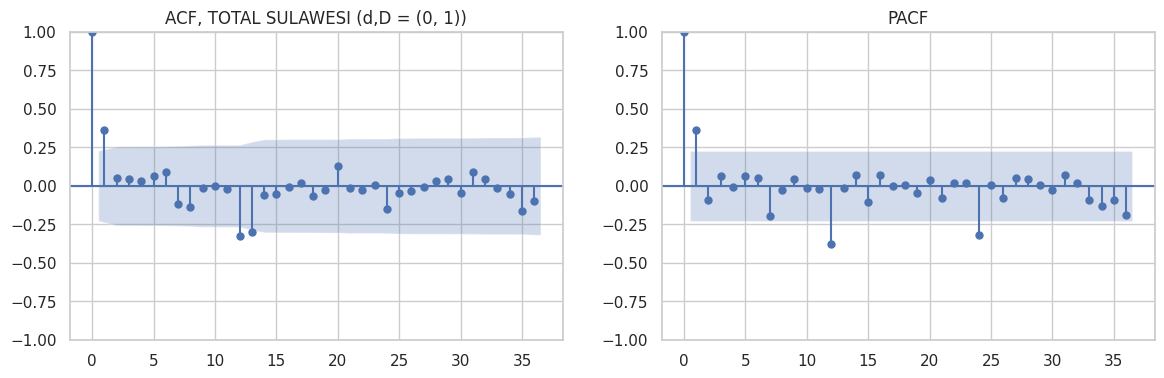

In [ ]:
p = TOTAL
judul = {(0, 0): "Level (hasil keputusan Box-Cox)", (0, 1): f"Diff musiman (D=1, s={S})", (1, 0): "Diff biasa (d=1)", (1, 1): "Diff musiman + biasa"}
fig = make_subplots(rows=2, cols=2, subplot_titles=[judul[k] for k in KOMBINASI])
for i, k in enumerate(KOMBINASI):
    z = tahap[p][k]
    fig.add_trace(go.Scatter(x=z.index, y=z.values, mode="lines", showlegend=False), row=i // 2 + 1, col=i % 2 + 1)
    fig.add_hline(y=float(z.mean()), line_dash="dash", line_color="red", row=i // 2 + 1, col=i % 2 + 1)
fig.update_layout(height=520, title=f"{p}: tiap kombinasi differencing"); fig.show()

z = tahap[p][orde_dD[p]]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(z, lags=min(36, len(z) // 2 - 1), ax=ax[0]); plot_pacf(z, lags=min(36, len(z) // 2 - 1), ax=ax[1], method="ywm")
ax[0].set_title(f"ACF, {p} (d,D = {orde_dD[p]})"); ax[1].set_title("PACF")
plt.show()

Gunakan ACF/PACF di atas sebagai petunjuk: lonjakan pada lag 1-2 menunjukkan p, q non-musiman; lonjakan pada lag 12, 24 menunjukkan P, Q musiman.

## 5. Identifikasi dan Estimasi Model

Pencarian grid kecil atas (p, q, P, Q) dengan d dan D dari bagian 4, dipilih berdasarkan **AIC** pada data latih.
Dilakukan dua varian: **SARIMAX** (eksogen `X1` dan `X2` dengan lag terpilih) dan **SARIMA** tanpa eksogen sebagai pembanding.
Model dibangun pada Y hasil keputusan Box-Cox; ramalan dikembalikan ke skala asli.

In [ ]:
def eksog_ext(p, n_known, idx_fut):
    # eksogen = nilai aktual sampai n_known, lalu rata-rata bulanan 36 bulan terakhir untuk bulan-bulan idx_fut; kemudian digeser sesuai lag
    kol = {}
    for c in EXOG:
        s = data[c][p].astype(float).iloc[:n_known]
        rata = s.iloc[-36:].groupby(s.iloc[-36:].index.month).mean()
        fut = pd.Series([rata[m] for m in idx_fut.month], index=idx_fut)
        ext = eks_skala(c, pd.concat([s, fut]))
        kol[c] = ext.shift(lag_pilih[p][c])
    return pd.DataFrame(kol)

def eksog_aktual(p):
    # eksogen aktual (tanpa nilai prediksi), digeser sesuai lag
    return pd.DataFrame({c: eks_skala(c, data[c][p].astype(float)).shift(lag_pilih[p][c]) for c in EXOG})

def siapkan(p, use_exog):
    y = transform_y(data[TARGET][p], p).iloc[START_LAG:]
    ex = eksog_aktual(p).loc[y.index] if (use_exog and EXOG) else None
    return y, ex

def fit(y, ex, order, sorder):
    m = SARIMAX(y, exog=ex, order=order, seasonal_order=sorder, trend="n" if (order[1] or sorder[1]) else "c",
                enforce_stationarity=False, enforce_invertibility=False)
    return m.fit(disp=False, maxiter=200)

def grid_search(y, ex, d, D, pmax=2, qmax=2, Pmax=1, Qmax=1):
    best, tabel = None, []
    for p_, q_, P_, Q_ in itertools.product(range(pmax+1), range(qmax+1), range(Pmax+1), range(Qmax+1)):
        try:
            r = fit(y, ex, (p_, d, q_), (P_, D, Q_, S))
            tabel.append(((p_, d, q_), (P_, D, Q_, S), r.aic, r.bic))
            if best is None or r.aic < best[2]: best = ((p_, d, q_), (P_, D, Q_, S), r.aic)
        except Exception:
            continue
    return best, pd.DataFrame(tabel, columns=["order", "seasonal", "AIC", "BIC"]).sort_values("AIC")

pilihan = {}
for p in MODEL_PROV:
    d, D = orde_dD[p]
    for var, ue in [("SARIMAX", True), ("SARIMA", False)]:
        y, ex = siapkan(p, ue)
        ytr = y.iloc[:-TEST]; extr = ex.iloc[:-TEST] if ex is not None else None
        best, tab = grid_search(ytr, extr, d, D)
        pilihan[(p, var)] = best
        print(f"{p:18s} {var:8s} -> order={best[0]} seasonal={best[1]} AIC={best[2]:.1f}")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelih

SULAWESI UTARA     SARIMAX  -> order=(2, 0, 0) seasonal=(1, 0, 1, 12) AIC=28.0


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SULAWESI UTARA     SARIMA   -> order=(0, 0, 2) seasonal=(1, 0, 1, 12) AIC=241.8


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelih

GORONTALO          SARIMAX  -> order=(2, 0, 2) seasonal=(0, 0, 1, 12) AIC=389.3
GORONTALO          SARIMA   -> order=(2, 0, 2) seasonal=(1, 0, 1, 12) AIC=592.7
SULAWESI TENGAH    SARIMAX  -> order=(0, 0, 2) seasonal=(0, 1, 1, 12) AIC=487.8
SULAWESI TENGAH    SARIMA   -> order=(2, 0, 2) seasonal=(1, 1, 1, 12) AIC=665.3
SULAWESI BARAT     SARIMAX  -> order=(0, 1, 2) seasonal=(0, 1, 1, 12) AIC=231.5
SULAWESI BARAT     SARIMA   -> order=(0, 1, 2) seasonal=(0, 1, 1, 12) AIC=425.2
SULAWESI SELATAN   SARIMAX  -> order=(2, 0, 2) seasonal=(0, 1, 1, 12) AIC=372.0
SULAWESI SELATAN   SARIMA   -> order=(2, 0, 2) seasonal=(0, 1, 1, 12) AIC=491.1
SULAWESI TENGGARA  SARIMAX  -> order=(1, 0, 2) seasonal=(0, 1, 1, 12) AIC=450.5
SULAWESI TENGGARA  SARIMA   -> order=(0, 0, 2) seasonal=(0, 1, 1, 12) AIC=569.2


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



TOTAL SULAWESI     SARIMAX  -> order=(0, 0, 2) seasonal=(0, 1, 1, 12) AIC=305.5
TOTAL SULAWESI     SARIMA   -> order=(1, 0, 2) seasonal=(0, 1, 1, 12) AIC=466.4


## 6. Evaluasi pada Data Uji (12 bulan terakhir)

Tiga ramalan SARIMAX/SARIMA dibandingkan dengan naif musiman:
- **SARIMAX (eksogen aktual)**: memakai nilai eksogen sebenarnya pada periode uji. Ini **batas atas yang tidak realistis**, karena saat meramal sungguhan nilai itu belum diketahui.
- **SARIMAX (eksogen diprediksi)**: eksogen periode uji diisi rata-rata bulanan 36 bulan sebelumnya, sama seperti kondisi peramalan sebenarnya.
- **SARIMA**: tanpa eksogen.

In [ ]:
def metrik(a, f):
    a, f = np.asarray(a, dtype=float), np.asarray(f, dtype=float)
    return {"MAPE (%)": np.mean(np.abs((a - f) / a)) * 100, "RMSE": np.sqrt(np.mean((a - f) ** 2)), "MAE": np.mean(np.abs(a - f))}

eval_rows, fc_test, model_train = [], {}, {}
for p in MODEL_PROV:
    yfull = data[TARGET][p]
    atest = yfull.iloc[-TEST:]
    idx_test = yfull.index[-TEST:]
    n_latih_all = len(yfull) - TEST

    y, ex = siapkan(p, True)
    order, sorder, _ = pilihan[(p, "SARIMAX")]
    r = fit(y.iloc[:-TEST], ex.iloc[:-TEST], order, sorder)
    model_train[(p, "SARIMAX")] = r
    ex_akt = ex.iloc[-TEST:]
    ex_pred = eksog_ext(p, n_latih_all, idx_test).loc[idx_test]
    fc_test[(p, "SARIMAX (eksogen aktual)")] = inv_series(r.get_forecast(TEST, exog=ex_akt).predicted_mean, p)
    fc_test[(p, "SARIMAX (eksogen diprediksi)")] = inv_series(r.get_forecast(TEST, exog=ex_pred).predicted_mean, p)

    y2, _ = siapkan(p, False)
    order2, sorder2, _ = pilihan[(p, "SARIMA")]
    r2 = fit(y2.iloc[:-TEST], None, order2, sorder2)
    model_train[(p, "SARIMA")] = r2
    fc_test[(p, "SARIMA")] = inv_series(r2.get_forecast(TEST).predicted_mean, p)

    for nm in ["SARIMAX (eksogen aktual)", "SARIMAX (eksogen diprediksi)", "SARIMA"]:
        eval_rows.append({"Provinsi": p, "Model": nm, **metrik(atest, fc_test[(p, nm)])})
    eval_rows.append({"Provinsi": p, "Model": "Naif musiman", **metrik(atest, yfull.shift(S).iloc[-TEST:])})

evaluasi = pd.DataFrame(eval_rows).set_index(["Provinsi", "Model"]).round(2)
display(evaluasi)

# model terpilih per provinsi: SARIMAX hanya bila eksogen yang DIPREDIKSI memberi MAPE lebih kecil daripada SARIMA
terpilih = {}
for p in MODEL_PROV:
    m_x = evaluasi.loc[(p, "SARIMAX (eksogen diprediksi)"), "MAPE (%)"]
    m_s = evaluasi.loc[(p, "SARIMA"), "MAPE (%)"]
    terpilih[p] = "SARIMAX" if (PILIH_MODEL_OTOMATIS and EXOG and m_x < m_s) or (not PILIH_MODEL_OTOMATIS and EXOG) else "SARIMA"
pd.DataFrame({"Model terpilih": terpilih})

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



MAPE (%)       RMSE        MAE
Provinsi          Model                                                       
SULAWESI UTARA    SARIMAX (eksogen aktual)          7.24    1937.20    1546.18
                  SARIMAX (eksogen diprediksi)      9.49    3241.63    2238.69
                  SARIMA                           15.54    4470.71    3730.41
                  Naif musiman                     15.93    4726.82    3528.41
GORONTALO         SARIMAX (eksogen aktual)         13.18    3380.22    2288.22
                  SARIMAX (eksogen diprediksi)     41.43    9529.74    6992.27
                  SARIMA                          103.61   14718.26   12944.32
                  Naif musiman                     42.50   14921.25   10100.73
SULAWESI TENGAH   SARIMAX (eksogen aktual)          5.58    8036.79    5164.05
                  SARIMAX (eksogen diprediksi)     29.87   24103.96   20570.40
                  SARIMA                           31.15   24757.37   22439.30
                  Naif musiman                     39.06   28140.67   24481.14
SULAWESI BARAT    SARIMAX (eksogen aktual)          7.19    2533.69    2205.76
                  SARIMAX (eksogen diprediksi)     24.99   10349.64    8631.37
                  SARIMA                           25.04   11555.88    8657.18
                  Naif musiman                     34.92   12001.39   10734.04
SULAWESI SELATAN  SARIMAX (eksogen aktual)          7.23   55458.13   38482.30
                  SARIMAX (eksogen diprediksi)     21.36  123939.33   92064.21
                  SARIMA                           19.79  121578.64   87631.89
                  Naif musiman                     21.79  148330.23  107195.77
SULAWESI TENGGARA SARIMAX (eksogen aktual)          6.48    6082.87    3890.36
                  SARIMAX (eksogen diprediksi)     16.97   13587.92    9328.26
                  SARIMA                           20.02   15128.45   10795.39
                  Naif musiman                     15.68   10471.04    8160.03
TOTAL SULAWESI    SARIMAX (eksogen aktual)          4.77   45252.43   34748.66
                  SARIMAX (eksogen diprediksi)     16.63  160307.94  123147.48
                  SARIMA                           15.59  160334.56  119874.45
                  Naif musiman                     13.93  147427.38  109899.01

,Model terpilih
SULAWESI UTARA,SARIMAX
GORONTALO,SARIMAX
SULAWESI TENGAH,SARIMAX
SULAWESI BARAT,SARIMAX
SULAWESI SELATAN,SARIMA
SULAWESI TENGGARA,SARIMAX
TOTAL SULAWESI,SARIMA


In [ ]:
fig = make_subplots(rows=int(np.ceil(len(MODEL_PROV) / 2)), cols=2, subplot_titles=MODEL_PROV)
warna = {"SARIMAX (eksogen aktual)": "#d62728", "SARIMAX (eksogen diprediksi)": "#ff7f0e", "SARIMA": "#1f77b4"}
for i, p in enumerate(MODEL_PROV):
    r_, c_ = i // 2 + 1, i % 2 + 1
    ya = data[TARGET][p].iloc[-36:]
    fig.add_trace(go.Scatter(x=ya.index, y=ya.values, name="Aktual", line=dict(color="black"), showlegend=(i == 0), legendgroup="Aktual"), row=r_, col=c_)
    for nm, w in warna.items():
        s_ = fc_test[(p, nm)]
        fig.add_trace(go.Scatter(x=s_.index, y=s_.values, name=nm, line=dict(color=w, dash="dash"), showlegend=(i == 0), legendgroup=nm), row=r_, col=c_)
fig.update_layout(height=300 * int(np.ceil(len(MODEL_PROV) / 2)), title="Ramalan pada data uji", hovermode="x unified")
fig.show()

Bacalah tabel dengan kritis. Bila SARIMAX dengan eksogen **diprediksi** tidak lebih baik dari SARIMA (atau naif musiman), tambahan eksogen belum membantu
dan model yang lebih sederhana lebih layak dipakai. Selisih besar antara SARIMAX "aktual" dan "diprediksi" menunjukkan seberapa bergantung model pada pengetahuan eksogen masa depan.

## 7. Diagnostik Residual

,Model,LB p (lag 12),LB p (lag 24),JB p (normalitas)
Provinsi,,,,
SULAWESI UTARA,SARIMAX,0.421,0.747,0.000
GORONTALO,SARIMAX,0.631,0.638,0.135
SULAWESI TENGAH,SARIMAX,0.881,0.994,0.188
SULAWESI BARAT,SARIMAX,0.008,0.104,0.000
SULAWESI SELATAN,SARIMA,0.850,0.630,0.555
SULAWESI TENGGARA,SARIMAX,0.918,0.504,0.278
TOTAL SULAWESI,SARIMA,0.343,0.159,0.271


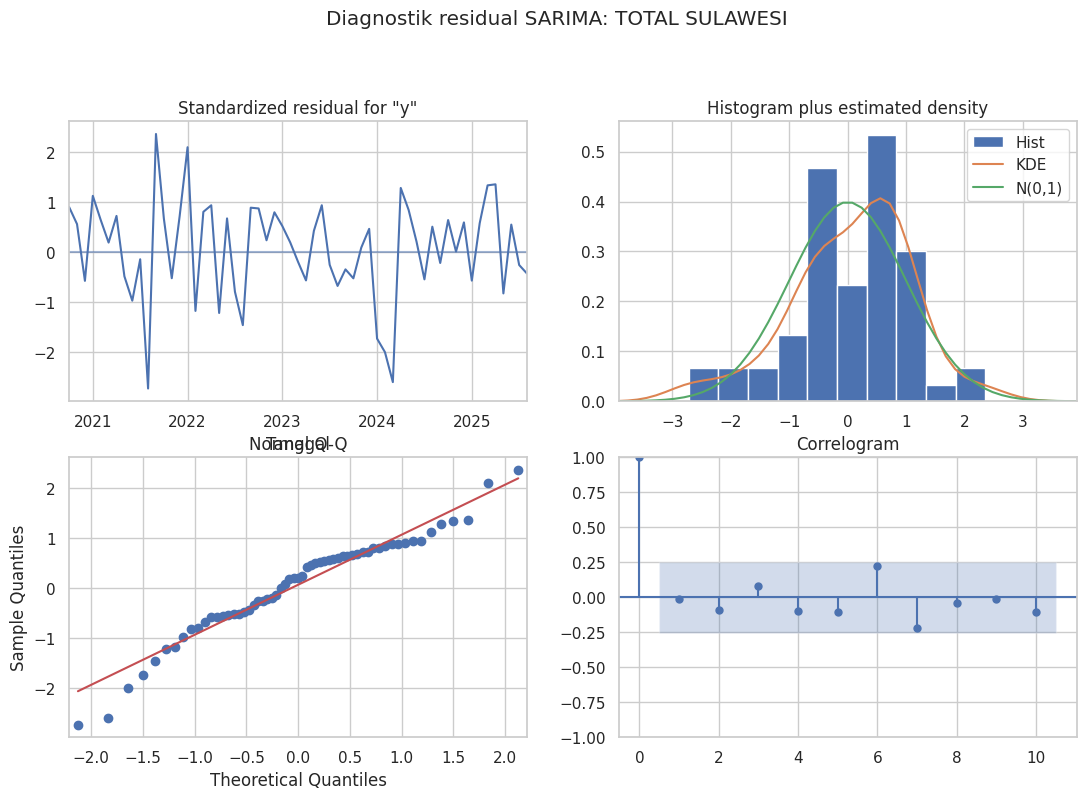

In [ ]:
def diagnostik(r, nama, var):
    res = r.resid.iloc[max(S, 13):]
    lb = acorr_ljungbox(res, lags=[12, 24], return_df=True)
    jb = jarque_bera(res)
    return {"Provinsi": nama, "Model": var, "LB p (lag 12)": round(lb["lb_pvalue"].iloc[0], 3), "LB p (lag 24)": round(lb["lb_pvalue"].iloc[1], 3),
            "JB p (normalitas)": round(jb[1], 3)}

dg = pd.DataFrame([diagnostik(model_train[(p, terpilih[p])], p, terpilih[p]) for p in MODEL_PROV]).set_index("Provinsi")
display(dg)

p = TOTAL
model_train[(p, terpilih[p])].plot_diagnostics(figsize=(13, 8)); plt.suptitle(f"Diagnostik residual {terpilih[p]}: {p}", y=1.02); plt.show()

Ljung-Box p > 0,05 berarti residual tidak berautokorelasi (model sudah menangkap pola). Jarque-Bera p > 0,05 berarti residual mendekati normal. Pelanggaran ringan normalitas tidak menggugurkan model, tetapi selang kepercayaan perlu dibaca hati-hati. Residual dihitung pada skala hasil Box-Cox.

## 8. Peramalan 12 Bulan ke Depan

Model terpilih dilatih ulang pada **seluruh data bermodel**, lalu meramal `H` bulan setelah data terakhir. Eksogen yang belum diketahui diisi
**rata-rata bulanan 36 bulan terakhir** (pola musiman); lag eksogen membuat sebagian langkah awal memakai nilai aktual. Ini asumsi sederhana dan transparan;
bila ada proyeksi resmi (misalnya prakiraan BMKG untuk `X2`), ganti nilainya pada `eksog_ext`.
Ramalan dikembalikan dari skala Box-Cox ke skala asli; hasil kembalian dari transformasi nonlinear lebih tepat dibaca sebagai nilai median daripada rata-rata.

In [ ]:
hasil_fc, model_final = {}, {}
for p in MODEL_PROV:
    var = terpilih[p]
    ue = (var == "SARIMAX")
    y, ex = siapkan(p, ue)
    order, sorder, _ = pilihan[(p, var)]
    r = fit(y, ex, order, sorder)
    ef = eksog_ext(p, len(data[TARGET]), fidx).loc[fidx] if ue else None
    if ef is not None:
        assert not ef.isna().any().any(), f"Eksogen masa depan tidak lengkap: {p}"
    f = r.get_forecast(H, exog=ef)
    ci = f.conf_int(alpha=.05)
    hasil_fc[p] = pd.DataFrame({"Ramalan": inv_series(f.predicted_mean, p),
                                "Bawah 95%": inv_series(ci.iloc[:, 0], p), "Atas 95%": inv_series(ci.iloc[:, 1], p)})
    model_final[p] = r

fig = make_subplots(rows=int(np.ceil(len(MODEL_PROV) / 2)), cols=2, subplot_titles=[f"{p} ({terpilih[p]})" for p in MODEL_PROV])
for i, p in enumerate(MODEL_PROV):
    r_, c_ = i // 2 + 1, i % 2 + 1
    ya = data[TARGET][p].iloc[-48:]
    h = hasil_fc[p]
    fig.add_trace(go.Scatter(x=ya.index, y=ya.values, name="Aktual", line=dict(color="black"), showlegend=(i == 0), legendgroup="a"), row=r_, col=c_)
    fig.add_trace(go.Scatter(x=h.index, y=h["Atas 95%"], line=dict(width=0), showlegend=False, hoverinfo="skip"), row=r_, col=c_)
    fig.add_trace(go.Scatter(x=h.index, y=h["Bawah 95%"], fill="tonexty", fillcolor="rgba(214,39,40,.2)", line=dict(width=0), name="95% CI", showlegend=(i == 0), legendgroup="c"), row=r_, col=c_)
    fig.add_trace(go.Scatter(x=h.index, y=h["Ramalan"], name="Ramalan", line=dict(color="#d62728"), showlegend=(i == 0), legendgroup="r"), row=r_, col=c_)
fig.update_layout(height=300 * int(np.ceil(len(MODEL_PROV) / 2)), title=f"Ramalan {H} bulan ke depan", hovermode="x unified")
fig.show()

hasil_fc[TOTAL].round(0)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



,Ramalan,Bawah 95%,Atas 95%
2026-09-01,1046462.0,767610.0,1388424.0
2026-10-01,748207.0,516257.0,1043670.0
2026-11-01,527853.0,348032.0,763362.0
2026-12-01,246582.0,144106.0,390781.0
2027-01-01,207512.0,117395.0,336737.0
2027-02-01,255992.0,150539.0,403843.0
2027-03-01,715812.0,490744.0,1003642.0
2027-04-01,1155653.0,836756.0,1549917.0
2027-05-01,786488.0,545316.0,1092780.0
2027-06-01,354326.0,219977.0,536758.0


In [ ]:
# ringkasan: total 12 bulan ke depan vs 12 bulan terakhir
rg = []
for p in MODEL_PROV:
    a = data[TARGET][p].iloc[-12:].sum(); b = hasil_fc[p]["Ramalan"].sum()
    rg.append({"Provinsi": p, "Model": terpilih[p], "Total 12 bln terakhir (aktual)": a, "Total 12 bln ke depan (ramalan)": b, "Perubahan (%)": (b / a - 1) * 100})
pd.DataFrame(rg).set_index("Provinsi").round(1)

,Model,Total 12 bln terakhir (aktual),Total 12 bln ke depan (ramalan),Perubahan (%)
Provinsi,,,,
SULAWESI UTARA,SARIMAX,270236.1,291272.0,7.8
GORONTALO,SARIMAX,279720.4,252975.1,-9.6
SULAWESI TENGAH,SARIMAX,932526.5,862890.3,-7.5
SULAWESI BARAT,SARIMAX,403408.8,354370.3,-12.2
SULAWESI SELATAN,SARIMA,5579155.6,4891438.2,-12.3
SULAWESI TENGGARA,SARIMAX,649975.3,614231.5,-5.5
TOTAL SULAWESI,SARIMA,8115022.7,7274051.6,-10.4


## 9. Simpan Hasil

In [ ]:
nama_file = f"hasil_sarimax_{PULAU_PILIH.lower()}.xlsx"
with pd.ExcelWriter(nama_file) as w:
    tabel_bc.drop(columns=[]).to_excel(w, sheet_name="BoxCox")
    pd.DataFrame(tabel_lag).to_excel(w, sheet_name="Lag_Eksogen", index=False)
    tabel_stas.to_excel(w, sheet_name="Uji_Stasioner")
    tabel_dD.to_excel(w, sheet_name="Orde_dD")
    evaluasi.to_excel(w, sheet_name="Evaluasi_Holdout")
    dg.to_excel(w, sheet_name="Diagnostik")
    for p, d_ in hasil_fc.items():
        d_.to_excel(w, sheet_name=f"Ramalan_{p[:20]}")
files.download(nama_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>